In [45]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (1).zip


In [46]:
import zipfile
import os

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("data")

print("Files extracted successfully!")

os.listdir("data")

Files extracted successfully!


['DescriptionDataCoSupplyChain.csv',
 'DataCoSupplyChainDataset.csv',
 'tokenized_access_logs.csv']

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported.")

Libraries imported.


In [48]:
df = pd.read_csv(
    "data/DataCoSupplyChainDataset.csv",
    encoding= "latin1"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (180519, 53)


## 1. Structural Overview

First understanding the dataset's dimensions, structure, data types and overall composition.

In [49]:
# Dataset Dimensions
rows, columns = df.shape

print("Number of Rows:", rows)
print("Number of Columns:", columns)
print("Total Records:", df.size)

Number of Rows: 180519
Number of Columns: 53
Total Records: 9567507


In [50]:
# First five records:
display(df.head())

# Last five records:
display(df.tail())

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,EE. UU.,XXXXXXXXX,Maria,1005,Peterson,XXXXXXXXX,Home Office,NY,1322 Broad Glade,11207.0,7,Fan Shop,40.640930,-73.942711,Pacific Asia,Shanghái,China,1005,1/16/2016 3:40,26043,1004,0.0,0.00,65177,399.980011,0.10,1,399.980011,399.980011,40.000000,Eastern Asia,Shanghái,CLOSED,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,EE. UU.,XXXXXXXXX,Ronald,9141,Clark,XXXXXXXXX,Corporate,CA,7330 Broad Apple Moor,93304.0,7,Fan Shop,35.362545,-119.018700,Pacific Asia,Hirakata,Japón,9141,1/16/2016 1:34,26037,1004,4.0,0.01,65161,399.980011,-1.55,1,399.980011,395.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,EE. UU.,XXXXXXXXX,John,291,Smith,XXXXXXXXX,Corporate,CT,97 Burning Landing,6010.0,7,Fan Shop,41.629959,-72.967155,Pacific Asia,Adelaide,Australia,291,1/15/2016 21:00,26024,1004,8.0,0.02,65129,399.980011,0.36,1,399.980011,391.980011,141.110001,Oceania,Australia del Sur,PENDING,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,Puerto Rico,XXXXXXXXX,Mary,2813,Smith,XXXXXXXXX,Consumer,PR,2585 Silent Autumn Landing,725.0,7,Fan Shop,18.213350,-66.370575,Pacific Asia,Adelaide,Australia,2813,1/15/2016 20:18,26022,1004,12.0,0.03,65126,399.980011,0.48,1,399.980011,387.980011,186.229996,Oceania,Australia del Sur,PENDING_PAYMENT,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.949997,383.980011,Shipping on time,0,45,Fishing,Caguas,Puerto Rico,XXXXXXXXX,Andrea,7547,Ortega,XXXXXXXXX,Consumer,PR,697 Little Meadow,725.0,7,Fan Shop,18.290380,-66.370613,Pacific Asia,Nagercoil,India,7547,1/15/2016 18:54,26018,1004,16.0,0.04,65113,399.980011,0.44,1,399.980011,383.980011,168.949997,South Asia,Tamil Nadu,PENDING_PAYMENT,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 18:54,Standard Class


In [51]:
print("COLUMN NAMES:\n")

for col in df.columns:
  print(col)

COLUMN NAMES:

Type
Days for shipping (real)
Days for shipment (scheduled)
Benefit per order
Sales per customer
Delivery Status
Late_delivery_risk
Category Id
Category Name
Customer City
Customer Country
Customer Email
Customer Fname
Customer Id
Customer Lname
Customer Password
Customer Segment
Customer State
Customer Street
Customer Zipcode
Department Id
Department Name
Latitude
Longitude
Market
Order City
Order Country
Order Customer Id
order date (DateOrders)
Order Id
Order Item Cardprod Id
Order Item Discount
Order Item Discount Rate
Order Item Id
Order Item Product Price
Order Item Profit Ratio
Order Item Quantity
Sales
Order Item Total
Order Profit Per Order
Order Region
Order State
Order Status
Order Zipcode
Product Card Id
Product Category Id
Product Description
Product Image
Product Name
Product Price
Product Status
shipping date (DateOrders)
Shipping Mode


In [52]:
# Display column datatypes
print(df.dtypes)

Type                              object
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                   object
Late_delivery_risk                 int64
Category Id                        int64
Category Name                     object
Customer City                     object
Customer Country                  object
Customer Email                    object
Customer Fname                    object
Customer Id                        int64
Customer Lname                    object
Customer Password                 object
Customer Segment                  object
Customer State                    object
Customer Street                   object
Customer Zipcode                 float64
Department Id                      int64
Department Name                   object
Latitude                         float64
Longitude                        float64
Market          

In [53]:
print("Data Type Distribution:\n")
print(df.dtypes.value_counts())

Data Type Distribution:

object     24
float64    15
int64      14
Name: count, dtype: int64


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [55]:
# Memory usage of individual columns
memory_usage = df.memory_usage(deep=True)

print("Memory usage by columns:\n")
display(memory_usage.sort_values(ascending=False).head(10))

#Total memory usage
total_memory = memory_usage.sum() / (1024**2)

print(f"Total Dataframe memory: {total_memory:.2f} MB")

Memory usage by columns:



,0
Product Image,21472196
Product Name,15185259
Customer Street,12448069
shipping date (DateOrders),11463307
order date (DateOrders),11462774
Delivery Status,11444558
Order State,11373105
Shipping Mode,11160401
Category Name,11139429
Order Region,11126163


Total Dataframe memory: 298.92 MB


### Intital Observation

- The dataset contains 180,519 records and 53 columns.
- It includes numerical, categorical and data-related attributes.
- The dataset contains information about customers, products, orders, shipping and sales performance.
- We have to investigate further for missing values, incorrect data types and potential data quality issues.

## 2. Missing value Analysis

Missing values can affect statistical calculations and analytical conclusions.
We will identify missing values, measure their proportion and visualize their distribution.

In [56]:
# Calculation of missing values
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_count / len(df)) *100

# Summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})

# Displaying columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662


<function matplotlib.pyplot.show(close=None, block=None)>

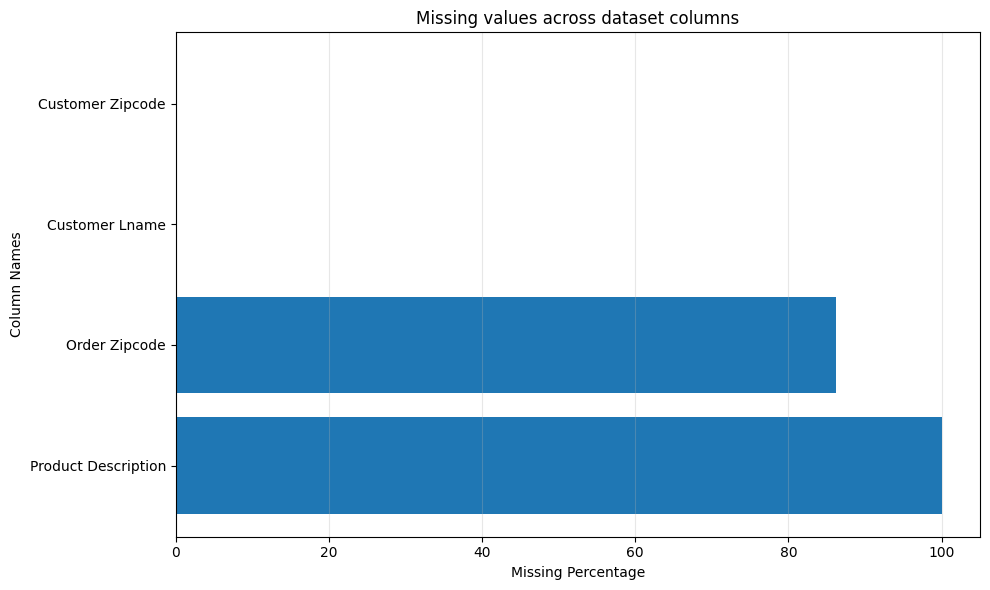

In [57]:
# Missing values bar chart

plt.figure(figsize = (10 , 6))

plt.barh(
    missing_summary.index,
    missing_summary['Missing Percentage']
)

plt.title('Missing values across dataset columns')
plt.xlabel('Missing Percentage')
plt.ylabel('Column Names')

plt.xlim(0, 105)
plt.grid(axis='x', alpha = 0.3)

plt.tight_layout()
plt.show



### Interpretation

The missing value analysis explains important data quality issues in two columns.

1. Product Discription is completely empty, making it unsuitable
   for further analysis.

2. Order Zipcode has approximately 86.24% missing values,
   limiting its reliability for geographical analysis.

3. Customer Lname and Customer Zipcode have very few missing
   values and are unlikely to significantly affect the overall
   dataset.

Therefore, missing values should be handled according to their
analytical importance rather than removing all affected records.

In [58]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)
print(
    "Duplicate Percentage:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Total Duplicate Rows: 0
Duplicate Percentage: 0.0 %


### Duplicate Analysis

The dataset contains zero exact duplicate rows.

However, multiple records can share the same Order ID because
an individual order may contain multiple product items.
Therefore, duplicate Order IDs should not automatically be
considered duplicate records.

In [59]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=np.number)

# Generate descriptive statictics
display(numerical_columns.describe().T)

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


In [60]:
business_metrics = [
    'Sales',
    'Benefit per order',
    'Order Profit Per Order',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Quantity',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Order Item Product Price'
]

display(df[business_metrics].describe().T)

,count,mean,std,min,25%,50%,75%,max
Sales,180519.0,203.772096,132.273077,9.99000,119.980003,199.919998,299.950012,1999.989990
Benefit per order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
Order Item Discount,180519.0,20.664741,21.800901,0.00000,5.400000,14.000000,29.990000,500.000000
Order Item Discount Rate,180519.0,0.101668,0.070415,0.00000,0.040000,0.100000,0.160000,0.250000
Order Item Quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
Days for shipping (real),180519.0,3.497654,1.623722,0.00000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.00000,2.000000,4.000000,4.000000,4.000000
Order Item Product Price,180519.0,141.232550,139.732492,9.99000,50.000000,59.990002,199.990005,1999.989990


In [61]:
categorical_columns = [
    'Market',
    'Order Region',
    'Shipping Mode',
    'Customer Segment',
    'Category Name',
    'Delivery Status',
    'Order Status'
]

for col in categorical_columns:
  print(f"\n{'='*50}")
  print(f"Value Counts: {col}")
  print('='*50)

  display(df[col].value_counts())


Value Counts: Market


,count
Market,
LATAM,51594
Europe,50252
Pacific Asia,41260
USCA,25799
Africa,11614



Value Counts: Order Region


,count
Order Region,
Central America,28341
Western Europe,27109
South America,14935
Oceania,10148
Northern Europe,9792
Southeast Asia,9539
Southern Europe,9431
Caribbean,8318
West of USA,7993



Value Counts: Shipping Mode


,count
Shipping Mode,
Standard Class,107752
Second Class,35216
First Class,27814
Same Day,9737


... (4 outputs left out)


Value Counts: Delivery Status


,count
Delivery Status,
Late delivery,98977
Advance shipping,41592
Shipping on time,32196
Shipping canceled,7754



Value Counts: Order Status


,count
Order Status,
COMPLETE,59491
PENDING_PAYMENT,39832
PROCESSING,21902
PENDING,20227
CLOSED,19616
ON_HOLD,9804
SUSPECTED_FRAUD,4062
CANCELED,3692
PAYMENT_REVIEW,1893


In [62]:
# Check whether selected columns contain identical values

column_pairs = [
    ('Benefit per order', 'Order Profit Per Order'),
    ('Sales per customer', 'Order Item Total'),
    ('Category Id', 'Product Category Id'),
    ('Product Card Id', 'Order Item Cardprod Id'),
    ('Customer Id', 'Order Customer Id')
]

for col1, col2 in column_pairs:

    result = df[col1].equals(df[col2])

    print(f"{col1} vs {col2}: {result}")

Benefit per order vs Order Profit Per Order: True
Sales per customer vs Order Item Total: True
Category Id vs Product Category Id: True
Product Card Id vs Order Item Cardprod Id: True
Customer Id vs Order Customer Id: True


In [63]:
# Count unique values in each column

unique_counts = df.nunique()

print("Columns with only one unique value:")
display(unique_counts[unique_counts == 1])

print("\nColumns with the highest number of unique values:")
display(unique_counts.sort_values(ascending=False).head(10))

Columns with only one unique value:


,0
Customer Email,1
Customer Password,1
Product Status,1



Columns with the highest number of unique values:


,0
Order Item Id,180519
order date (DateOrders),65752
Order Id,65752
shipping date (DateOrders),63701
Benefit per order,21998
Order Profit Per Order,21998
Customer Id,20652
Order Customer Id,20652
Latitude,11250
Customer Street,7458


In [64]:
# Conversion of date columns into datetime format

df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'],
    errors='coerce'
)

df['shipping date (DateOrders)'] = pd.to_datetime(
    df['shipping date (DateOrders)'],
    errors= 'coerce'
)

print(df[['order date (DateOrders)',
          'shipping date (DateOrders)']].dtypes)


order date (DateOrders)       datetime64[ns]
shipping date (DateOrders)    datetime64[ns]
dtype: object


## 5. Exploratory Data Analysis and Visualizations

We now explore the dataset through visualizations designed
to investigate supply chain performance, shipping efficiency,
sales distribution and profitability.

### 5.1 Delivery Performance Distribution

Our first objective is to understand how reliably customer
orders are delivered.

### Visualization 1: Delivery performance

In [65]:
# Creating a dataset with one record per order

order_df = df.drop_duplicates(subset='Order Id').copy()

print("Total Item Records:", len(df))
print("Unique Orders:", len(order_df))

Total Item Records: 180519
Unique Orders: 65752


In [66]:
status_consistency = df.groupby('Order Id')['Delivery Status'].nunique()

print("Orders with inconsistent delivery status:",
      (status_consistency > 1).sum())

Orders with inconsistent delivery status: 0


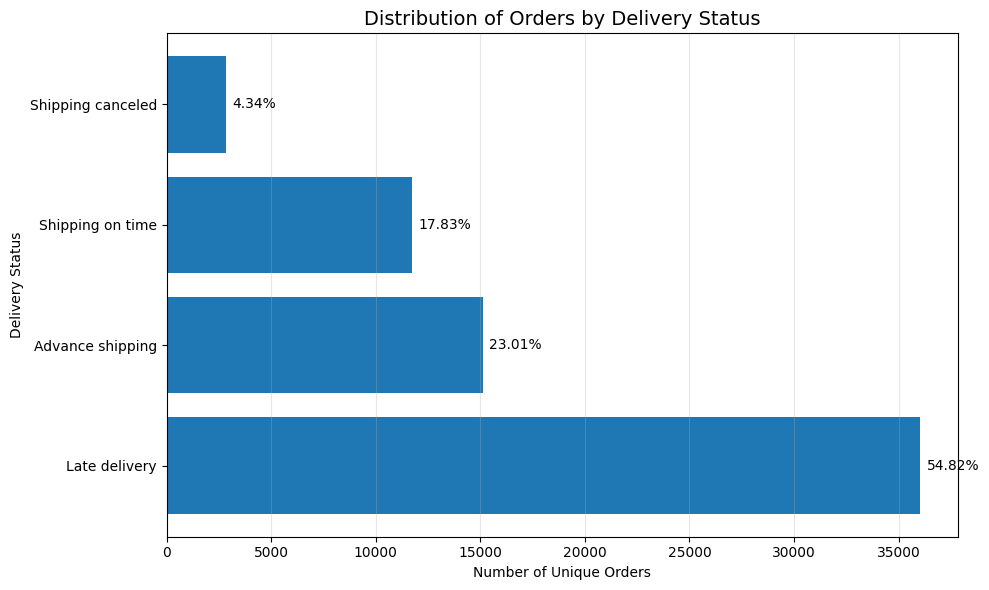

In [67]:
# Count unique orders by delivery status
delivery_counts = order_df['Delivery Status'].value_counts()

# Calculate percentages
delivery_percentages = (
    delivery_counts / delivery_counts.sum()
) * 100

# Create visualization
plt.figure(figsize=(10, 6))

bars = plt.barh(
    delivery_counts.index,
    delivery_counts.values
)

# Add percentage labels
for bar, percentage in zip(bars, delivery_percentages):

    plt.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height()/2,
        f'{percentage:.2f}%',
        va='center'
    )

plt.title('Distribution of Orders by Delivery Status',
          fontsize=14)

plt.xlabel('Number of Unique Orders')
plt.ylabel('Delivery Status')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The analysis reveals that approximately 54.82% of unique orders
are classified as late deliveries, indicating a substantial
delivery reliability issue in the dataset.

Only 17.83% of orders are classified as shipping on time,
while 23.01% are delivered ahead of schedule. Additionally,
4.34% of orders are marked as canceled.

This suggests that delivery delays are an important area
requiring further investigation.

### Visualization 2: Delivery performance by shipping mode.

In [68]:
# Caluculating the percentage of late deliveries for each shipping mode

late_by_mode = (
    order_df.groupby('Shipping Mode')['Delivery Status'].apply(lambda x: (x == 'Late delivery').mean() *100).sort_values(ascending=False)

)
print(late_by_mode)

Shipping Mode
First Class       95.267388
Second Class      76.717796
Same Day          46.149538
Standard Class    38.131930
Name: Delivery Status, dtype: float64


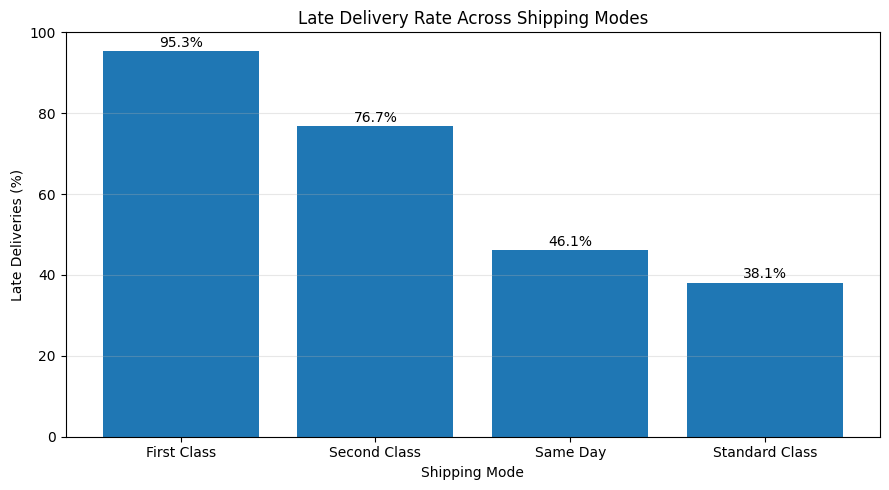

In [69]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    late_by_mode.index,
    late_by_mode.values
)

for bar, value in zip(bars, late_by_mode.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.1f}%',
        ha='center'
    )

plt.title('Late Delivery Rate Across Shipping Modes')
plt.xlabel('Shipping Mode')
plt.ylabel('Late Deliveries (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The analysis reveals a substantial difference in late delivery rates across shipping modes. First Class has the highest late delivery rate at 95.3%, followed by Second Class at 76.7%. Surprisingly, Standard Class has the lowest late delivery rate at 38.1%, even lower than Same Day shipping at 46.1%.

This suggests that selecting a faster shipping mode does not necessarily guarantee more reliable delivery in this dataset. Further investigation into scheduled and actual shipping durations may help explain this pattern.

This is not proof that faster shipping causes delays. We should investigate the scheduled delivery expectations before drawing conclusions.

### Visualization 3: Actual vs scheduled shipping time

In [70]:
shipping_comparison = (
    order_df.groupby('Shipping Mode')[
        ['Days for shipping (real)', 'Days for shipment (scheduled)']
    ].mean())
print(shipping_comparison)

                Days for shipping (real)  Days for shipment (scheduled)
Shipping Mode                                                          
First Class                     2.000000                            1.0
Same Day                        0.483618                            0.0
Second Class                    4.001565                            2.0
Standard Class                  3.996898                            4.0


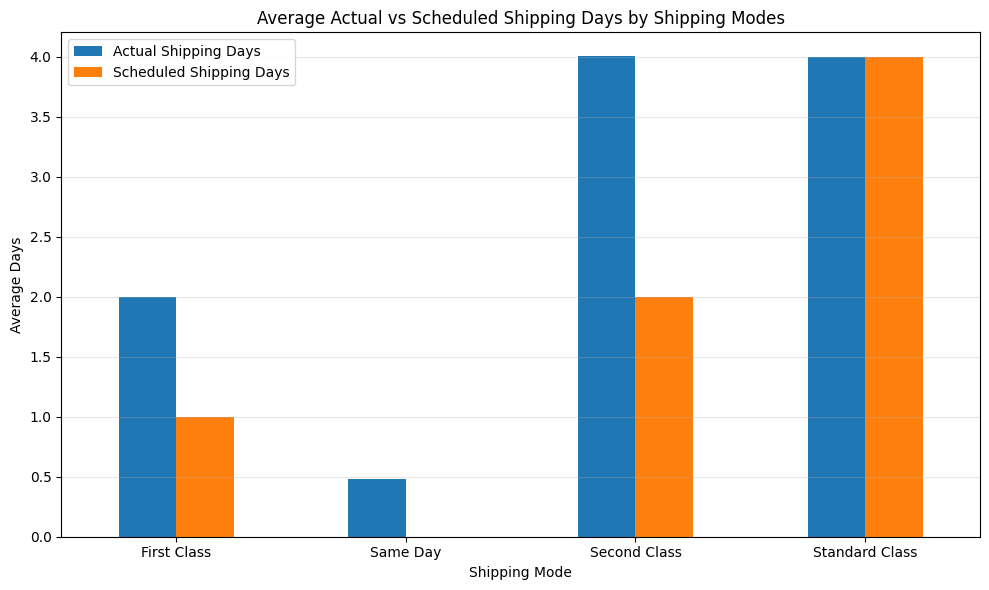

In [71]:
shipping_comparison.plot(
    kind = 'bar',
    figsize = (10,6)
)

plt.title('Average Actual vs Scheduled Shipping Days by Shipping Modes')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Days')
plt.xticks(rotation=0)
plt.legend(['Actual Shipping Days', 'Scheduled Shipping Days'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Visualization 4: Which product categories generate the most revenue?

In [72]:
category_sales = (
    df.groupby('Category Name')['Sales'].sum().sort_values(ascending=False).head(10)
)
print(category_sales)

Category Name
Fishing                 6.929654e+06
Cleats                  4.431943e+06
Camping & Hiking        4.118426e+06
Cardio Equipment        3.694843e+06
Women's Apparel         3.147800e+06
Water Sports            3.113845e+06
Men's Footwear          2.891758e+06
Indoor/Outdoor Games    2.888994e+06
Shop By Sport           1.309522e+06
Computers               6.630000e+05
Name: Sales, dtype: float64


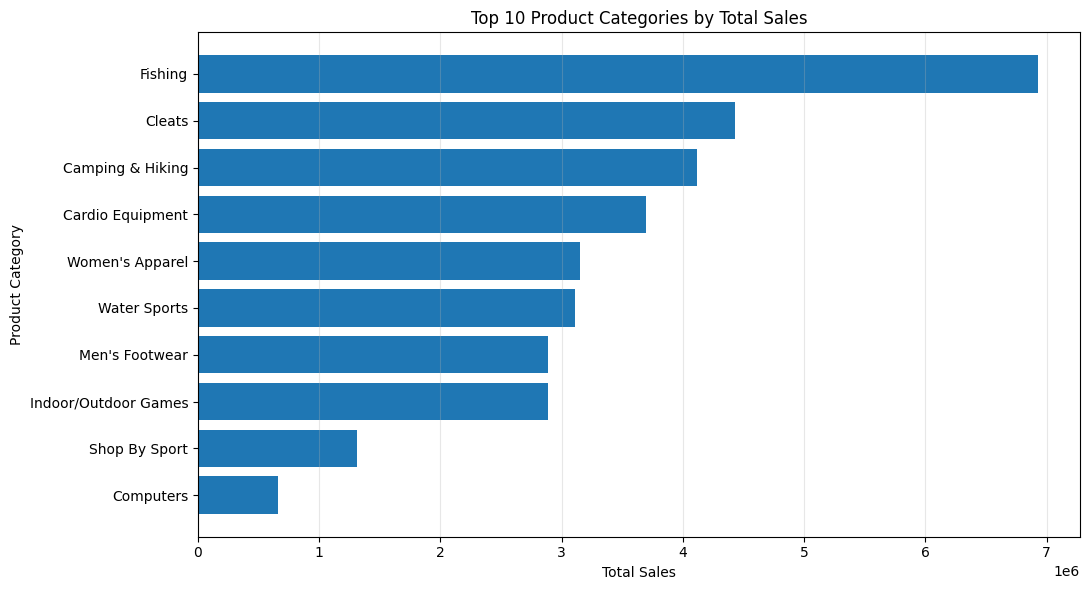

In [73]:
plt.figure(figsize=(11, 6))

plt.barh(category_sales.index, category_sales.values)

plt.title('Top 10 Product Categories by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Category')
plt.gca().invert_yaxis()

plt.grid(axis = 'x', alpha= 0.3)
plt.tight_layout()
plt.show()

### Interpretation

The category-wise sales analysis reveals that Fishing is the highest revenue-generating product category, with a substantial lead over the other categories. Cleats and Camping & Hiking occupy the second and third positions, respectively. This indicates that sales contribution is not evenly distributed across product categories.

However, high sales do not automatically mean high profitability. We will investigate profitability separately rather than assuming that the highest-selling categories are the most profitable.

### Visualization 5: How do sales change over time?

In [74]:
monthly_sales = (
    df.groupby(df['order date (DateOrders)'].dt.to_period('M'))['Sales'].sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

print(monthly_sales.head())

order date (DateOrders)
2015-01-01    1.051590e+06
2015-02-01    9.270099e+05
2015-03-01    1.051254e+06
2015-04-01    1.014463e+06
2015-05-01    1.050478e+06
Freq: MS, Name: Sales, dtype: float64


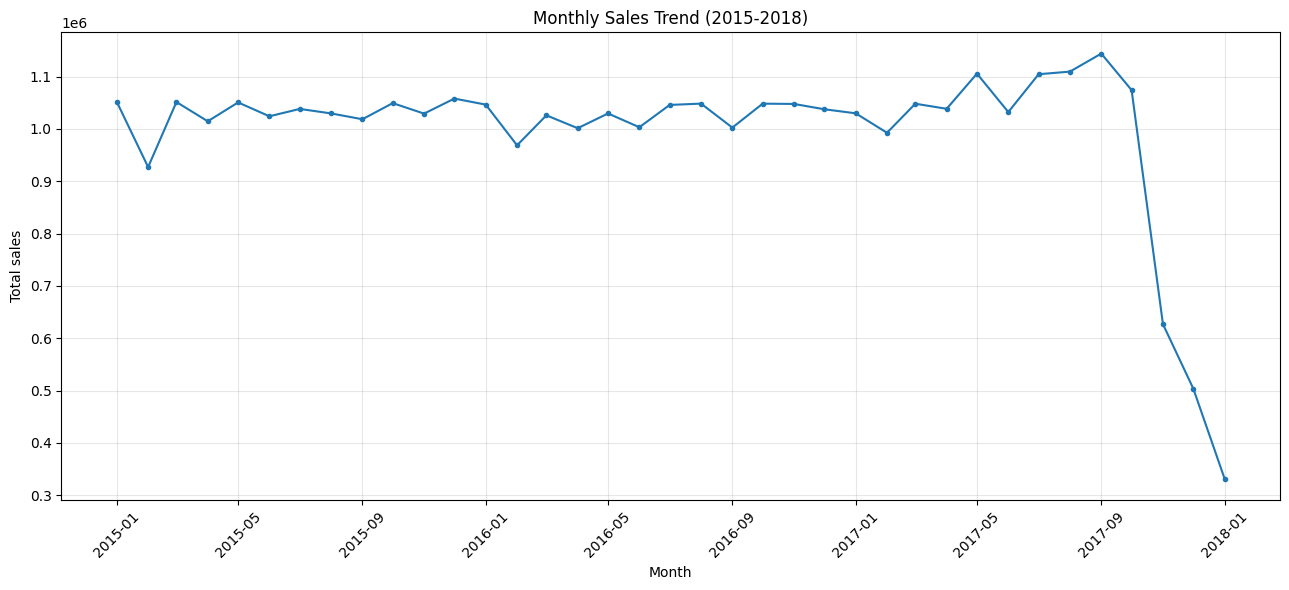

In [75]:
plt.figure(figsize=(13, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker= 'o',
    markersize = 3
)

plt.title('Monthly Sales Trend (2015-2018)')
plt.xlabel('Month')
plt.ylabel('Total sales')
plt.xticks(rotation = 45)
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

In [76]:
# check for incomplete data of final months

monthly_orders= (
    order_df.groupby(
        order_df['order date (DateOrders)'].dt.to_period('M')
    )['Order Id'].count()
)

monthly_records = (
    df.groupby(
        df['order date (DateOrders)'].dt.to_period('M')
    ).size()
)

monthly_check = pd.DataFrame({
    'Unique Orders': monthly_orders,
    'Items Records': monthly_records
})

print(monthly_check.tail(8))

                         Unique Orders  Items Records
order date (DateOrders)                              
2017-06                           1676           4951
2017-07                           1776           5318
2017-08                           1768           5305
2017-09                           1723           5189
2017-10                           2101           2255
2017-11                           2055           2055
2017-12                           2124           2124
2018-01                           2123           2123


In [77]:
monthly_analysis = pd.DataFrame({
    'Total Sales': df.groupby(
        df['order date (DateOrders)'].dt.to_period('M')
    )['Sales'].sum(),

    'Unique Orders': order_df.groupby(
        order_df['order date (DateOrders)'].dt.to_period('M')
    )['Order Id'].count(),

    'Item Records': df.groupby(
        df['order date (DateOrders)'].dt.to_period('M')
    ).size()
})

monthly_analysis['Items per Order'] = (
    monthly_analysis['Item Records'] /
    monthly_analysis['Unique Orders']
)

monthly_analysis['Sales per Order'] = (
    monthly_analysis['Total Sales'] /
    monthly_analysis['Unique Orders']
)

print(monthly_analysis.tail(8).round(2))

                         Total Sales  Unique Orders  Item Records  \
order date (DateOrders)                                             
2017-06                   1032086.49           1676          4951   
2017-07                   1104373.36           1776          5318   
2017-08                   1109337.17           1768          5305   
2017-09                   1143775.11           1723          5189   
2017-10                   1073994.17           2101          2255   
2017-11                    626914.38           2055          2055   
2017-12                    503910.82           2124          2124   
2018-01                    331650.12           2123          2123   

                         Items per Order  Sales per Order  
order date (DateOrders)                                    
2017-06                             2.95           615.80  
2017-07                             2.99           621.83  
2017-08                             3.00           627.45  
2017-09  

### Interpretation

Monthly sales remained relatively stable from January 2015 through September 2017. However, a significant decline appears from October 2017 onward.

Further investigation reveals that the decline is not explained by a reduction in order volume. The number of unique monthly orders remained around 2,100, while average items per order dropped from approximately 3 to just 1. Sales per order also declined substantially, from 663.83 in September 2017 to 156.22 in January 2018.

This suggests a major change in order composition or recorded sales values during the final months of the dataset. This pattern should be treated as a potential data-quality or business-pattern anomaly rather than automatically interpreted as declining demand.

### Visualization 6: Does a higher discount affect profitability?

In [78]:
# Divide discount rates into ranges
df['Discount Range'] = pd.cut(
    df['Order Item Discount Rate'],
    bins=[-0.01, 0.05, 0.10, 0.15, 0.20, 0.26],
    labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-25%']
)

discount_profit = (
    df.groupby('Discount Range', observed=False)['Benefit per order']
    .mean()
)

print(discount_profit)

Discount Range
0-5%      23.944523
5-10%     23.508290
10-15%    21.473808
15-20%    20.139751
20-25%    18.407092
Name: Benefit per order, dtype: float64


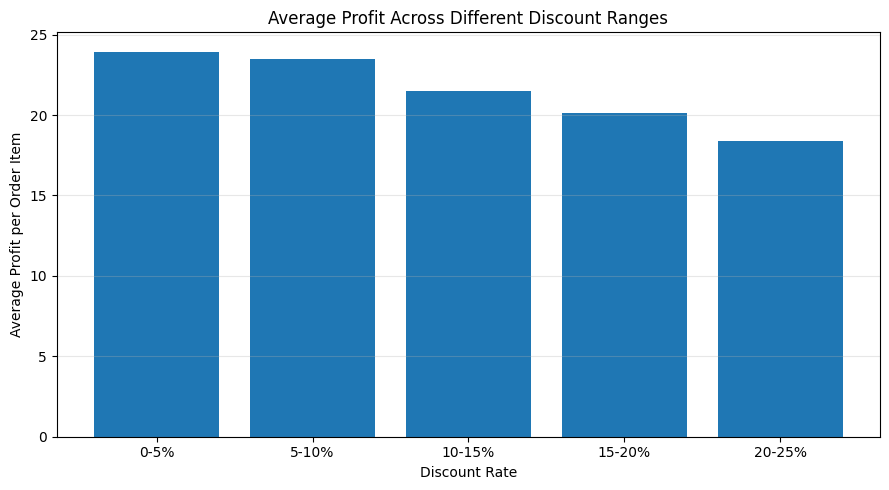

In [79]:
plt.figure(figsize=(9, 5))

plt.bar(
    discount_profit.index.astype(str),
    discount_profit.values
)

plt.title('Average Profit Across Different Discount Ranges')
plt.xlabel('Discount Rate')
plt.ylabel('Average Profit per Order Item')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The analysis reveals a consistent decline in average recorded profit as discount rates increase. Items in the 0–5% discount range have an average profit of approximately 23.94, whereas those in the 20–25% range have an average of 18.41.

This indicates a negative association between discount rates and recorded profitability in the dataset. However, this relationship alone does not establish that discounts directly cause lower profits, as product category, quantity and other factors may also influence profitability.

### Visualization 7: Which categories are actually profitable?

In [80]:
category_profit = (
    df.groupby('Category Name')['Benefit per order']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(category_profit)

Category Name
Computers               157.594593
Garden                   69.097128
Crafts                   52.750351
Cameras                  51.165203
Fishing                  43.649106
Children's Clothing      41.684202
Sporting Goods           35.066135
Music                    33.263410
Camping & Hiking         31.135230
Consumer Electronics     30.680742
Name: Benefit per order, dtype: float64


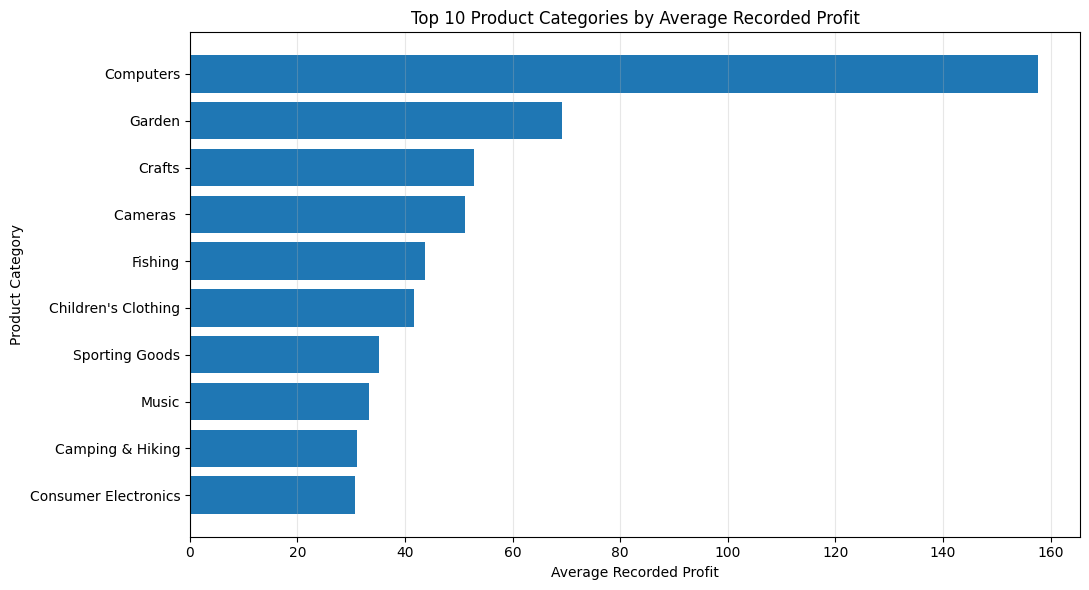

In [81]:
plt.figure(figsize=(11, 6))

plt.barh(
    category_profit.index,
    category_profit.values
)

plt.title('Top 10 Product Categories by Average Recorded Profit')
plt.xlabel('Average Recorded Profit')
plt.ylabel('Product Category')
plt.gca().invert_yaxis()

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The profitability analysis reveals that Computers has the highest average recorded profit per order item at approximately 157.59, followed by Garden at 69.10 and Crafts at 52.75.

Interestingly, Fishing, despite being the highest revenue-generating category in the previous analysis, ranks fifth in average profitability. This demonstrates that high sales revenue does not necessarily translate into the highest profit per item.

### Visualization 8: Profitability overview

In [82]:
print("Profitable items:",
      (df['Benefit per order'] > 0).sum())

print("Loss-making items:",
      (df['Benefit per order'] < 0).sum())

print("Zero-profit items:",
      (df['Benefit per order'] == 0).sum())

print("\nProfit summary:")
print(df['Benefit per order'].describe())

Profitable items: 145558
Loss-making items: 33784
Zero-profit items: 1177

Profit summary:
count    180519.000000
mean         21.974989
std         104.433526
min       -4274.979980
25%           7.000000
50%          31.520000
75%          64.800003
max         911.799988
Name: Benefit per order, dtype: float64


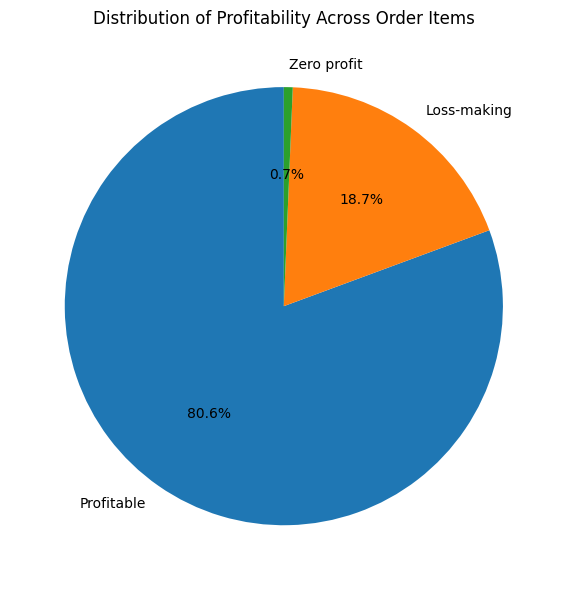

In [83]:
profit_counts = [
    (df['Benefit per order'] > 0).sum(),
    (df['Benefit per order'] < 0).sum(),
    (df['Benefit per order'] == 0).sum()
]

labels = ['Profitable', 'Loss-making', 'Zero profit']

plt.figure(figsize=(8, 6))

plt.pie(
    profit_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Profitability Across Order Items')
plt.tight_layout()
plt.show()

### Interpretation

Approximately 80.63% of order items generate positive profit, while 18.72% generate losses and 0.65% have zero profit.

Although most items are profitable, nearly one in five order items is loss-making. The profit distribution also contains extreme values, ranging from -4,274.98 to 911.80, suggesting substantial variation in profitability. These extreme observations should be investigated before drawing conclusions from average profit alone.

## Key Findings

1. **Delivery reliability is a major concern:** Approximately 54.82% of unique orders are classified as late deliveries, while only 17.83% are delivered on time.

2. **Faster shipping modes do not guarantee better delivery performance:** First Class has a 95.3% late delivery rate, compared with 38.1% for Standard Class. Actual shipping durations frequently exceed scheduled durations for faster shipping modes.

3. **Sales composition changes significantly toward the end of the dataset:** Monthly sales decline sharply from October 2017 onward, despite monthly order counts remaining relatively stable. Average items per order fall from approximately 3 to 1, suggesting a major change in order composition or data recording.

4. **Higher discounts are associated with lower average profitability:** Average recorded profit decreases from 23.94 in the 0–5% discount range to 18.41 in the 20–25% range.

5. **Revenue and profitability tell different stories:** Fishing generates the highest total sales, whereas Computers has the highest average recorded profit per order item. Additionally, approximately 18.72% of order items are loss-making.

## Data Limitations

- The dataset contains missing values, including 100% missing values in `Product Description` and approximately 86.24% missing values in `Order Zipcode`.
- Several columns contain redundant information, and some columns have constant values, providing little analytical value.
- The dataset contains customer-related personal information. Such fields were excluded from the analysis and should not be published.
- The final months show a significant change in average items per order and sales per order. This may reflect a change in order composition or data recording and requires further validation.
- The analysis identifies associations and patterns, not causal relationships.
- Profitability metrics contain extreme positive and negative values, which may influence averages.